# Planificación de velocidad y trayectoria para un agente autónomo en Tocancipá (Assetto Corsa)
**Física A: Hardware e Información · Proyecto final**

**Integrantes:** John Edward Rincón Aragón (202420895) · Samuel Zuluaga (202520012) · Samuel Beltrán López (202522601)

**Pregunta de investigación.** ¿En qué medida un modelo simplificado de un vehículo permite predecir y optimizar trayectorias de conducción que mantengan un buen rendimiento y estabilidad al ejecutarse en un entorno de simulación con física vehicular más detallada?

**Cómo la respondemos.** Comparamos la estimación matemática con las mediciones en Assetto Corsa; la bicicleta cinemática sirve como modelo de movimiento y verificación numérica. Evaluamos tiempo de vuelta, perfiles de velocidad, desviaciones respecto a la trayectoria objetivo y finalización de ensayos. Comparamos la línea central con la trayectoria optimizada para evaluar el aprovechamiento de la pista.

**Hipótesis.** Un modelo simplificado que incorpora geometría, adherencia, potencia y límites longitudinales puede identificar trayectorias de menor tiempo previsto que la línea central y producir referencias ejecutables en un simulador de física más detallada. La hipótesis se somete a prueba: completar una vuelta no basta si las velocidades o posiciones predichas difieren sustancialmente de las observadas.

## Índice
| Apartado | Contenido |
|---|---|
| 0 | Preparación y datos |
| 1 | Contexto |
| 2 | Modelo físico |
| 3 | Parámetros del vehículo |
| 4 | Calibración experimental |
| 5 | Geometría e integrales |
| 6 | Optimización de trayectoria |
| 7 | Agente conductor |
| 8 | Verificación numérica |
| 9 | Experimentación |
| 10 | Análisis de resultados |
| 11 | Conclusiones |
| 12 | Declaración de uso de IA |
| 13 | Referencias |

## 0. Preparación y datos
Se utiliza la campaña `20261126_185537`. Ejecutar desde `Proyecto_Fisica` o desde la carpeta del código; alternativamente definir `FISICA_DATOS`. No requiere iniciar Assetto Corsa.

In [1]:
from pathlib import Path
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from IPython.display import display
candidatos = [Path.cwd()/"proy entrega final"/"experimentos"/"20261126_185537", Path.cwd()/"experimentos"/"20261126_185537", Path.home()/"OneDrive"/"Documents"/"Proyecto_Fisica"/"proy entrega final"/"experimentos"/"20261126_185537"]
EXPERIMENTO = Path(os.environ.get("FISICA_DATOS", str(next((p for p in candidatos if (p/"parametros.json").exists()), candidatos[0]))))
PARAM = json.loads((EXPERIMENTO/"parametros.json").read_text(encoding="utf-8"))
TIPOS = ("central", "optimizada")
planes = {t: np.load(EXPERIMENTO/f"plan_{t}.npz") for t in TIPOS}
EST = {t: pd.read_csv(EXPERIMENTO/f"{t}_estimacion.csv") for t in TIPOS}
AC = {t: [pd.read_csv(EXPERIMENTO/f"{t}_ac_{i:02d}_raw.csv") for i in range(1,11)] for t in TIPOS}
resultados = {t: [json.loads((EXPERIMENTO/f"{t}_ac_{i:02d}.json").read_text()) for i in range(1,11)] for t in TIPOS}
assert all(r['completada'] for t in TIPOS for r in resultados[t]), "Hay vueltas incompletas."
L = float(planes['central']['meta']-planes['central']['inicio'])
grid = np.linspace(0,L,1001)
colores = dict(central='#2878b5', optimizada='#e88924')
plt.rcParams.update({'figure.figsize':(11,3.6),'axes.grid':True,'grid.alpha':.2,'figure.dpi':110})
def interp(d,col):
    s=np.maximum.accumulate(d.distance_m.to_numpy()); keep=np.r_[True,np.diff(s)>1e-8]
    return np.interp(grid,s[keep],d[col].to_numpy()[keep],left=np.nan,right=np.nan)
def media(A):
    A=np.asarray(A); count=np.isfinite(A).sum(axis=0)
    return np.divide(np.nansum(A,axis=0),count,out=np.full(A.shape[1],np.nan),where=count==len(A))
def perfil(t,col): return media([interp(d,col) for d in AC[t]])
p=planes['central']; sc=p['sc']-p['inicio']; mask=(sc>=0)&(sc<=L)
xy=lambda a: np.column_stack([np.interp(grid,sc,a[:,i]) for i in range(2)])
centro=xy(p['centro']); ruta=xy(planes['optimizada']['ruta'])
despl=np.linalg.norm(planes['optimizada']['ruta']-p['centro'],axis=1)
modificado=np.interp(grid,sc,despl)>0.01

import sys
CODIGO=Path.cwd()/"proy entrega final" if (Path.cwd()/"proy entrega final").is_dir() else Path.cwd()
sys.path.insert(0,str(CODIGO))
import modelado_fisico as mf
veh=mf.Vehiculo(**PARAM["vehiculo"])
G=mf.G


## 1. Contexto y aprovechamiento físico de la pista
La línea central es una trayectoria admisible, no necesariamente la de menor tiempo. El ancho de la pista es una oportunidad de optimización: modificar el recorrido cambia su longitud y su curvatura, y con ello las velocidades físicamente posibles. El objetivo no es minimizar distancia ni curvatura aisladamente, sino minimizar el tiempo estimado de vuelta dentro de las restricciones físicas y geométricas.

Assetto Corsa se utiliza como referencia de mayor complejidad física, no como sustituto de una prueba con un automóvil real. Tocancipá se representa con los bordes del mod del circuito. La conexión con Ingeniería de Sistemas y Computación consiste en discretizar el problema, buscar soluciones con restricciones, integrar sensores y actuadores y contrastar las predicciones con datos de simulación.

## 2. Modelo físico y supuestos
Bicicleta cinemática plana con una rueda equivalente por eje y huella rectangular. Se supone adherencia constante e isotrópica; se omiten la dinámica individual de neumáticos, suspensión, transferencia de carga, aerodinámica y caja de cambios.

### 2.1 Ecuaciones del modelo

**Estado y controles.** El estado es $(x, y, \psi, v)$: posición del eje trasero, orientación medida desde el eje $+x$ y rapidez. Los controles son el ángulo de las ruedas delanteras $\delta$ y la aceleración longitudinal $a$.

**Bicicleta cinemática.** Sin deslizamiento lateral, cada rueda avanza en la dirección en la que apunta. Por geometría, el eje trasero gira alrededor de un centro a distancia $R = L/\tan\delta$, y la velocidad angular es $v/R$:

$$\dot x = v\cos\psi,\qquad \dot y = v\sin\psi,\qquad \dot\psi = \frac{v}{L}\tan\delta,\qquad \dot v = a$$

Para seguir una curva de curvatura $\kappa = 1/R$ hace falta $\delta = \arctan(L\kappa)$, y el volante gira $\theta_{volante} = r_{dir}\,\delta$.

**Aceleración lateral.** Un cuerpo que recorre una curva de radio $R$ a rapidez $v$ necesita una aceleración centrípeta $a_{lat} = v^2/R = v^2\kappa$. Esa aceleración la produce la fricción entre neumáticos y asfalto.

**Círculo de fricción.** La fuerza de fricción máxima es $\mu m g$, así que la aceleración total, sumando la parte longitudinal (acelerar o frenar) y la lateral (girar), no puede superar $\mu g$:

$$a^2 + a_{lat}^2 \le (\mu g)^2 \quad\Rightarrow\quad a_{disp} = \sqrt{\max(0,(\mu g)^2 - (v^2\kappa)^2)}$$

**Velocidad máxima en curva.** Si toda la fricción se usa para girar, $m v^2/R = \mu m g$:

$$v_{max} = \sqrt{\frac{\mu g}{|\kappa|}} = \sqrt{\mu g R}$$

La masa se cancela: en el modelo, la velocidad en curva no depende de la masa.

**Potencia del motor.** Con potencia útil $P$, la fuerza de tracción es $F = P/v$. La aceleración queda limitada por el motor y por un tope (agarre de tracción):

$$a_{motor} = \min\left(a_{max},\ \frac{P}{m\,\max(v,0.5)}\right)$$

**Tramo con aceleración constante.** Entre dos puntos separados $\Delta s$, de $v^2 = v_0^2 + 2a\Delta s$ salen la pasada de aceleración y la de frenado, y la distancia de frenado:

$$v_{i+1} = \sqrt{v_i^2 + 2a\,\Delta s_i},\qquad d = \frac{v_0^2 - v_c^2}{2b}$$

**Tiempo de vuelta.** Con aceleración constante en cada tramo, la velocidad media es $(v_i + v_{i+1})/2$:

$$T = \sum_i \frac{2\Delta s_i}{v_i + v_{i+1}}$$

**Integración en el tiempo (Euler explícito).** Con paso $\Delta t$: $\mathbf{X}_{k+1} = \mathbf{X}_k + \dot{\mathbf{X}}_k\,\Delta t$, donde $\mathbf{X} = (x, y, \psi, v)$. Además, $\delta$ no puede cambiar más de $\dot\delta_{max}\Delta t$ por paso ni superar $\delta_{max}$.

### 2.2. Implementación del movimiento
Las derivadas se integran mediante Euler explícito, respetando los límites del giro.

**`modelado_fisico.py` — código original.**

```python
def derivadas_bicicleta(estado, aceleracion_m_s2, veh):
    """Ecuaciones: x'=v cos(psi); y'=v sin(psi); psi'=v tan(delta)/L; v'=a."""
    v = estado.velocidad_m_s  # Velocidad instantánea del carro.
    psi = estado.psi_rad  # Orientación actual del carro.
    delta = estado.delta_rad  # Ángulo actual de las ruedas delanteras.
    dx = v * math.cos(psi)  # Velocidad en eje Este [m/s].
    dy = v * math.sin(psi)  # Velocidad en eje Norte [m/s].
    dpsi = (v / veh.distancia_ejes_m) * math.tan(delta)  # Giro [rad/s].
    dv = aceleracion_m_s2  # Cambio de rapidez [m/s²].
    return np.array([dx, dy, dpsi, dv], dtype=float)

def paso_bicicleta(estado, aceleracion_m_s2, delta_objetivo_rad, dt_s, veh):
    """Un paso temporal de Euler; controla límite y rapidez de dirección."""
    # Comprueba una condición para separar datos válidos y casos excepcionales.
    if dt_s <= 0:
        raise ValueError('El tiempo debe ser positivo')
    objetivo = np.clip(delta_objetivo_rad, -veh.giro_ruedas_max_rad,
                       veh.giro_ruedas_max_rad)  # Límite mecánico.
    cambio_max = veh.velocidad_giro_ruedas_max_rad_s * dt_s  # Giro permitido.
    cambio = np.clip(objetivo - estado.delta_rad, -cambio_max, cambio_max)
    delta = float(estado.delta_rad + cambio)  # Nueva dirección de las ruedas.
    actual = Estado(estado.x, estado.y, estado.psi_rad, estado.velocidad_m_s,
                    delta)  # Usa el ángulo actualizado para estimar movimiento.
    derivadas = derivadas_bicicleta(actual, aceleracion_m_s2, veh)  # dx/dt, etc.
    valor_actual = np.array([actual.x, actual.y, actual.psi_rad,
                             actual.velocidad_m_s])  # Estado en vector NumPy.
    siguiente = valor_actual + derivadas * dt_s  # Euler: nuevo=actual+deriv*dt.
    return Estado(float(siguiente[0]), float(siguiente[1]), float(siguiente[2]),
                  max(0.0, float(siguiente[3])), delta)
```


### 2.3. Restricciones físicas

**`modelado_fisico.py` — código original.**

```python
def aceleracion_longitudinal_por_agarre(v_m_s, kappa, veh):
    """Obtiene aceleración longitudinal restante tras reservar adherencia para la curva."""
    a_lat = aceleracion_lateral(v_m_s, kappa)  # Parte del agarre usada al girar.
    libre_cuadrado = (veh.coef_friccion * G)**2 - a_lat**2  # Agar­re restante².
    return np.sqrt(np.maximum(0.0, libre_cuadrado))

def velocidad_maxima_curva(kappa, veh):
    """v_max=sqrt(mu*g/abs(kappa)); rectas admiten infinito localmente."""
    k = np.asarray(kappa, dtype=float)  # Funciona con escalar o array.
    with np.errstate(divide='ignore', invalid='ignore'):
        limites = np.where(np.abs(k) < EPS, np.inf,
                           np.sqrt(veh.coef_friccion * G / np.maximum(np.abs(k), EPS)))
    return float(limites) if limites.ndim == 0 else limites

def aceleracion_motor(v_m_s, veh):
    """Limita aceleración longitudinal simultáneamente por potencia y por tope del vehículo."""
    por_potencia = fuerza_por_potencia(v_m_s, veh) / veh.masa_kg  # a=F/m.
    return min(veh.aceleracion_max_m_s2, por_potencia)
```


## 3. Parámetros del vehículo
Porsche 991.2 GT2 RS, neumáticos Hypercar Road. Se utilizan los valores efectivos registrados en la campaña, distinguiendo lecturas directas, mediciones experimentales y supuestos nominales.

In [2]:
v=PARAM['vehiculo']
filas=[('Masa (kg)',v['masa_kg'],'Tomado directamente de Assetto Corsa (car.ini)'),('Potencia útil (W)',v['potencia_util_w'],'Tomado directamente de Assetto Corsa (maxPower; potencia útil aproximada)'),('Distancia entre ejes (m)',v['distancia_ejes_m'],'Tomado directamente de Assetto Corsa (suspensions.ini)'),('Relación de dirección',v['relacion_direccion'],'Tomado directamente de Assetto Corsa (car.ini)'),('Aceleración (m/s²)',v['aceleracion_max_m_s2'],'Tomado experimentalmente'),('Frenado (m/s²)',v['frenado_max_m_s2'],'Tomado experimentalmente'),('Coeficiente de fricción',v['coef_friccion'],'Tomado experimentalmente; isotropía supuesta'),('Largo (m)',v['largo_m'],'Supuesto nominal'),('Ancho (m)',v['ancho_m'],'Supuesto nominal'),('Giro máximo (°)',np.degrees(v['giro_ruedas_max_rad']),'Supuesto nominal'),('Rapidez de giro (°/s)',np.degrees(v['velocidad_giro_ruedas_max_rad_s']),'Supuesto nominal'),('Gravedad (m/s²)',G,'Constante física'),('Paso temporal (s)',PARAM['dt_control'],'Configuración del modelo'),('Tope del evaluador (m/s)',PARAM['tope_evaluador_m_s'],'Configuración numérica')]
display(pd.DataFrame(filas,columns=['Parámetro','Valor','Procedencia']).round(3))

,Parámetro,Valor,Procedencia
0,Masa (kg),1545.000,Tomado directamente de Assetto Corsa (car.ini)
1,Potencia útil (W),504881.969,Tomado directamente de Assetto Corsa (maxPower...
2,Distancia entre ejes (m),2.453,Tomado directamente de Assetto Corsa (suspensi...
3,Relación de dirección,10.500,Tomado directamente de Assetto Corsa (car.ini)
4,Aceleración (m/s²),6.353,Tomado experimentalmente
5,Frenado (m/s²),9.934,Tomado experimentalmente
6,Coeficiente de fricción,1.230,Tomado experimentalmente; isotropía supuesta
7,Largo (m),4.200,Supuesto nominal
8,Ancho (m),1.800,Supuesto nominal
9,Giro máximo (°),30.000,Supuesto nominal


## 4. Calibración experimental
Se realizaron pruebas de aceleración y frenado en recta en Assetto Corsa. Las capacidades longitudinales se aproximaron por medias ponderadas de las bandas de velocidad, $\bar a=\frac{\sum_i n_i a_i}{\sum_i n_i}$, y análogamente para el frenado: 6,353 y 9,934 m/s². Son valores representativos de un ensayo, no máximos certificados.

Para la fricción se tomó la mediana de los cinco mayores picos de desaceleración (12,0722 m/s²), obteniendo $\mu=12,0722/9,81\approx1,23$. Se aplica ese coeficiente longitudinal también en dirección lateral como supuesto de isotropía; no constituye una medición lateral directa.

## 5. Geometría de Tocancipá
La pista puede representarse mediante una curva parametrizada por su longitud de arco \(s\). Esta representación se toma directamente de las ecuaciones (1a–1c) propuestas por Kapania et al. (2015, p. 3), en su artículo A Sequential Two-Step Algorithm for Fast Generation of Vehicle Racing Trajectories. Si \(K(s)\) es la curvatura con signo y \(\psi_r(s)\) el rumbo medido desde el norte hacia el oeste, las coordenadas cartesianas de la trayectoria pueden obtenerse mediante las siguientes integrales:
$$\psi_r(s)=\psi_r(0)+\int_0^s K(z)\,dz$$
$$E(s)=E(0)-\int_0^s\sin(\psi_r(z))\,dz,\qquad N(s)=N(0)+\int_0^s\cos(\psi_r(z))\,dz.$$
La primera integral acumula cambios de orientación; las otras dos acumulan desplazamientos de la tangente. El código usa segmentos de longitud fija y el rumbo en el punto medio. En la campaña se emplearon directamente las coordenadas procesadas del circuito y sus bordes, no una reconstrucción por integración, evitando así deriva acumulada. La estación común se mide sobre la línea central.

**`modelado_fisico.py`**

```python
def integrar_pista_desde_curvatura_paper(curvaturas_menos1, ds_m=1.0,
                                         este_inicial=0.0, norte_inicial=0.0,
                                         psi_inicial_rad=0.0):
    """Integra las tres ecuaciones (1a–1c) de geometría del paper.

    psi_r(s) = psi_inicial + integral(K(z) dz)
    E(s) = E_inicial - integral(sin(psi_r(z)) dz)
    N(s) = N_inicial + integral(cos(psi_r(z)) dz)

    Se usa el método del punto medio en cada sección de longitud ds_m.
    Se supone K constante dentro de cada sección.
    """
    k = np.asarray(curvaturas_menos1, dtype=float)  # Curvatura de cada tramo.
    # Comprueba una condición para separar datos válidos y casos excepcionales.
    if k.ndim != 1 or not np.all(np.isfinite(k)) or ds_m <= 0:
        raise ValueError('Curvaturas 1D finitas y ds_m positivo requeridos')
    cambios_psi = k * ds_m  # Cambio angular de cada segmento: dpsi = K ds.
    psi = psi_inicial_rad + np.r_[0.0, np.cumsum(cambios_psi)]  # Ángulos en nodos.
    psi_medio = psi[:-1] + cambios_psi / 2  # Ángulo en la mitad de cada tramo.
    delta_este = -np.sin(psi_medio) * ds_m  # (1a) dE ≈ -sin(psi) ds.
    delta_norte = np.cos(psi_medio) * ds_m  # (1b) dN ≈ cos(psi) ds.
    este = este_inicial + np.r_[0.0, np.cumsum(delta_este)]  # Integra Este.
    norte = norte_inicial + np.r_[0.0, np.cumsum(delta_norte)]  # Integra Norte.
    return np.column_stack((este, norte)), psi

def curvaturas_de_puntos(puntos):
    """Curvatura con signo de círculos por cada tres puntos consecutivos.

    k = 2*det(B-A,C-A)/(|B-A| |C-B| |C-A|).
    Los extremos toman el valor de su vecino (aproximación).
    """
    p = validar_puntos(puntos, minimo=3)  # Necesitamos triples de puntos.
    ab = p[1:-1] - p[:-2]  # Vector A->B para todos los triples.
    bc = p[2:] - p[1:-1]  # Vector B->C para todos los triples.
    ac = p[2:] - p[:-2]  # Vector A->C para todos los triples.
    det = ab[:, 0] * ac[:, 1] - ab[:, 1] * ac[:, 0]  # Determinante 2D.
    denom = (np.linalg.norm(ab, axis=1) * np.linalg.norm(bc, axis=1)
             * np.linalg.norm(ac, axis=1))  # Producto de longitudes.
    # Comprueba una condición para separar datos válidos y casos excepcionales.
    if np.any(denom < EPS):
        raise ValueError('Segmento degenerado en curvatura')
    interior = 2 * det / denom  # Curvatura en los puntos interiores.
    return np.r_[interior[0], interior, interior[-1]]
```


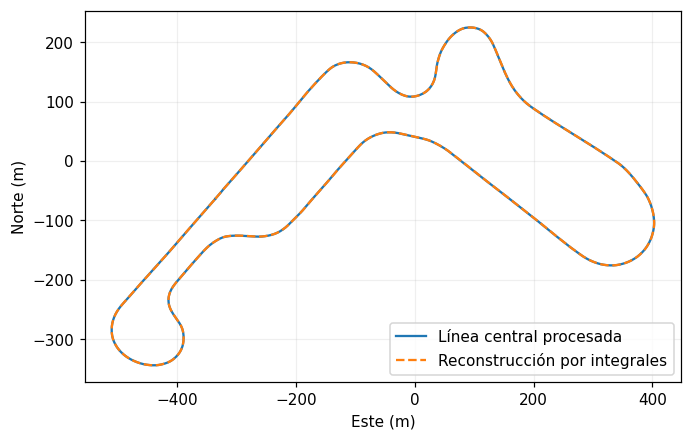

In [3]:
# Reconstrucción ilustrativa mediante integración; no es la ruta usada para conducir.
s_uniforme=np.linspace(0,L,2001); ds=s_uniforme[1]-s_uniforme[0]
xy_u=np.column_stack([np.interp(s_uniforme,grid,centro[:,i]) for i in range(2)])
k=mf.curvaturas_de_puntos(xy_u); rumbo=np.arctan2(-(xy_u[1,0]-xy_u[0,0]),xy_u[1,1]-xy_u[0,1])
recon,_=mf.integrar_pista_desde_curvatura_paper((k[:-1]+k[1:])/2,ds,*xy_u[0],rumbo)
fig,ax=plt.subplots(figsize=(7,5)); ax.plot(*centro.T,label='Línea central procesada'); ax.plot(*recon.T,'--',label='Reconstrucción por integrales'); ax.set(aspect='equal',xlabel='Este (m)',ylabel='Norte (m)');ax.legend();plt.show()

## 6. Optimización geométrica
Se identifican curvas mediante la curvatura suavizada (21 muestras, umbral 0,005 m⁻¹). Se seleccionan picos separados al menos 35 m. Para cada curva se prueban 36 configuraciones de ápice (temprano, medio o tardío), amplitudes interiores y exteriores y extensiones de maniobra. La trayectoria se expresa como $\mathbf P_i=\mathbf C_i+d_i\mathbf N_i$. Los desplazamientos se interpolan con una quintica de primera y segunda derivadas nulas en sus extremos. Se descartan candidatos incompatibles con los bordes o restricciones físicas; se conserva la mejora temporal superior al umbral de 0,02 s. La búsqueda es local y limitada, no exhaustiva.

**`conducir_fisica_optimizado.py` — interpolación:**
```python
def q(t):
        """Interpolación quintica, C2 en los puntos de control aislados."""
        t = np.clip(t, 0.0, 1.0)
        return t**3 * (10.0 - 15.0*t + 6.0*t*t)
```

**`modelado_fisico.py` — código original.**

```python
def normales_izquierdas(puntos):
    """Vector normal izquierdo N=(-sin(psi), cos(psi)) en cada punto."""
    psi = orientaciones_de_puntos(puntos)  # Dirección tangente de cada punto.
    return np.column_stack((-np.sin(psi), np.cos(psi)))
```

### Perfil de velocidad y criterio de selección
`estimaciones.py` calcula el límite local por curvatura, recorre hacia atrás para anticipar el frenado y hacia adelante para limitar la aceleración por potencia y agarre. El tiempo se estima sumando $2\Delta s_i/(v_i+v_{i+1})$. El perfil empieza en reposo en la salida del experimento.

**`modelado_fisico.py` — código original.**

```python
def acelerar_en_distancia(v_inicial, a_m_s2, distancia_m):
    # Ecuación cinemática v_f²=v_i²+2*a*ds (a constante en este segmento).
    """Aplica v_f² = v_i² + 2aΔs en cada segmento de aceleración o frenado."""
    return math.sqrt(max(0.0, v_inicial**2 + 2 * a_m_s2 * distancia_m))
```


## 7. Agente conductor
El agente recibe el estado y la trayectoria con su perfil de velocidad; aplica correcciones de dirección y órdenes de acelerador y freno. Es un controlador autónomo basado en reglas, sin aprendizaje ni reoptimización en marcha. Se emplea el mismo algoritmo en ambas modalidades.

**`conducir_fisica_optimizado.py` — generación de referencias:**
```python
def controlar(conductor, evaluacion, s_ruta, s_actual, t):
    """Convierte el objetivo de seguimiento en órdenes de acelerador, freno y dirección para vJoy."""
    i = int(np.clip(np.searchsorted(s_ruta, s_actual, side='right') - 1,
                    0, len(s_ruta) - 2))
    velocidad = float(evaluacion.velocidades_m_s[i + 1])
    conductor.agregar_ordenes([Orden(
        inicio_s=t, fin_s=t + 0.001,
        direccion_rad=float(evaluacion.direcciones_rad[i]),
        velocidad_objetivo_m_s=velocidad
    )])
    return velocidad
```

## 8. Verificación numérica del modelo
Se comprueban tres casos analíticos: curvatura circular $1/R$, frenado en recta $d=v_0^2/(2b)$ y giro constante $R=L/\tan\delta$. Se utiliza el paso de control de 0,02 s. Estas pruebas verifican la implementación, no la fidelidad respecto a Assetto Corsa.

In [4]:
R=50.;dt=PARAM['dt_control']; vv=100/3.6
ang=np.linspace(0,2*np.pi,501); circ=np.c_[R*np.cos(ang),R*np.sin(ang)]
k=float(np.mean(mf.curvaturas_de_puntos(circ)))
e=mf.Estado(0,0,0,vv,0)
while e.velocidad_m_s>0: e=mf.paso_bicicleta(e,-veh.frenado_max_m_s2,0,dt,veh)
d=mf.distancia_frenado(vv,0,veh.frenado_max_m_s2)
delta=float(mf.curvatura_a_direccion(1/R,veh));e2=mf.Estado(0,0,0,20,delta); pts=[]
for _ in range(int(2*np.pi*R/20/dt)):
    e2=mf.paso_bicicleta(e2,0,delta,dt,veh);pts.append((e2.x,e2.y))
x,y=np.array(pts).T; A,B,C=np.linalg.lstsq(np.c_[x,y,np.ones_like(x)],-(x*x+y*y),rcond=None)[0]; rn=np.sqrt(A*A/4+B*B/4-C)
tab=pd.DataFrame([['Curvatura (1/m)',1/R,k],['Frenado (m)',d,e.x],['Radio de giro (m)',R,rn]],columns=['Prueba','Analítico','Numérico']);tab['Error absoluto']=abs(tab.Numérico-tab.Analítico);display(tab)

,Prueba,Analítico,Numérico,Error absoluto
0,Curvatura (1/m),0.02000,0.020000,5.204170e-17
1,Frenado (m),38.83801,39.116085,2.780750e-01
2,Radio de giro (m),50.00000,50.000133,1.333336e-04


# 9. Experimentación
## 9.1. Metodología experimental
Se utilizaron los parámetros físicos definidos en los apartados 3 y 4. Se realizaron diez vueltas independientes en Assetto Corsa por cada trayectoria (central y optimizada), desde reposo y con el mismo algoritmo de conducción. Se alternó el orden por pares. Se compara la predicción física con el promedio de las diez ejecuciones de cada modalidad.

## 9.2. Optimización geométrica de la trayectoria
El optimizador modifica los ápices para minimizar $T=\int ds/v(s)$, considerando el compromiso entre distancia y curvatura. Una menor magnitud de curvatura permite una mayor velocidad lateralmente admisible, $v_{\max}=\sqrt{\mu g/|\kappa|}$, pero no garantiza por sí sola un menor tiempo. La tabla identifica las últimas decisiones de ápice registradas; los tramos modificados se identifican por desplazamientos superiores a 1 cm (tolerancia de visualización).

,Candidata,Estación (m),Ápice,Fracción interior,Fracción exterior,Extensión (m)
0,2,462.60,medio,0.85,0.70,130.0
1,8,1665.92,medio,0.85,0.95,130.0
2,9,1923.09,tardio,0.95,0.70,130.0
3,10,1987.13,temprano,0.95,0.70,130.0
4,11,2137.89,medio,0.99,0.70,85.0
5,12,2224.61,temprano,0.85,0.70,130.0


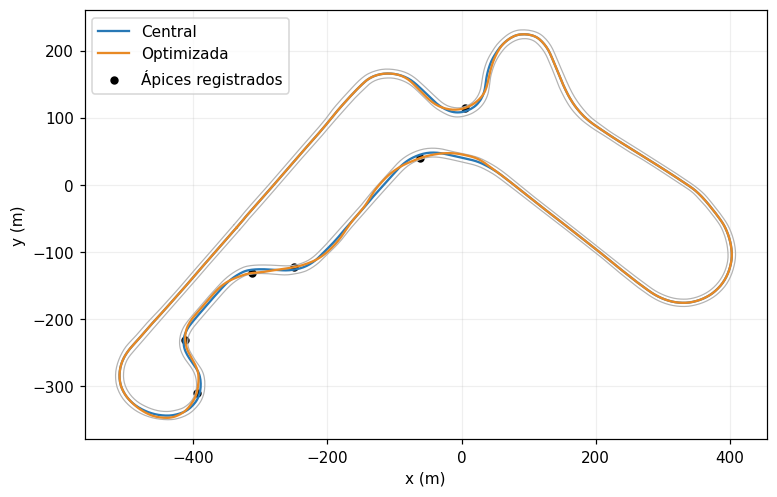

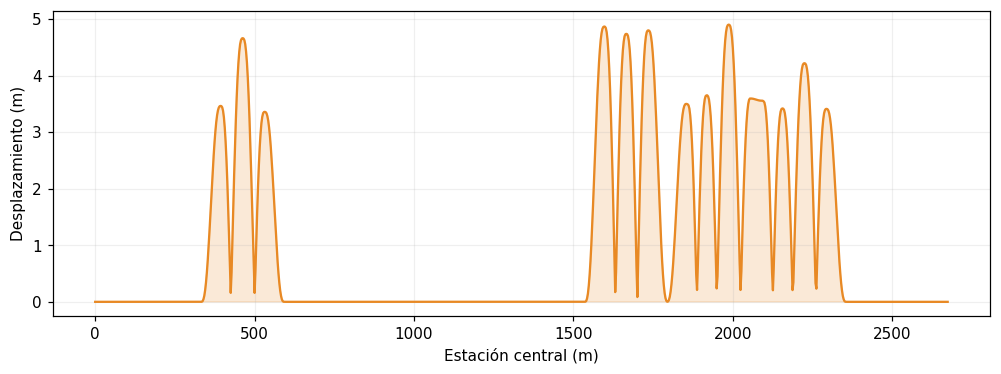

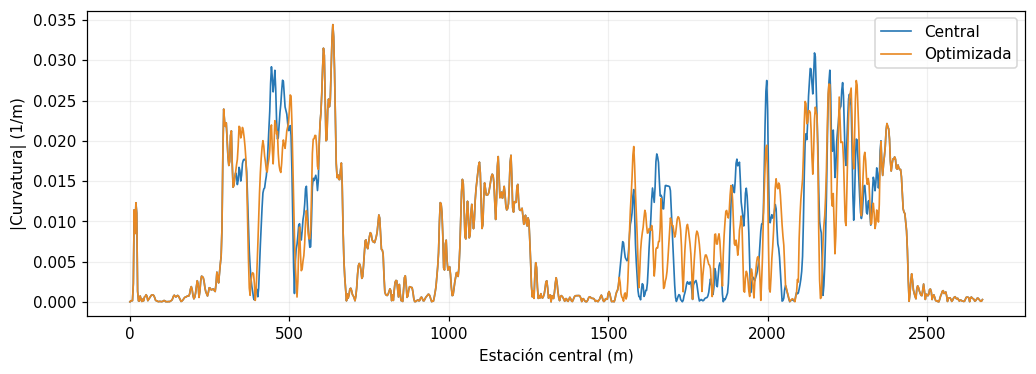

In [5]:
apices=pd.DataFrame(PARAM['apices_ultima_decision'])
if not apices.empty:
    apices['estacion_relativa_m']=apices.estacion_m-float(p['inicio'])
    display(apices[['curva','estacion_relativa_m','tipo','interior','exterior','extension_m']].rename(columns={'curva':'Candidata','estacion_relativa_m':'Estación (m)','tipo':'Ápice','interior':'Fracción interior','exterior':'Fracción exterior','extension_m':'Extensión (m)'}).round(2))
fig,ax=plt.subplots(figsize=(8,6))
for k in ['izquierdo','derecho']: ax.plot(*xy(p[k]).T,color='0.7',lw=.8)
ax.plot(*centro.T,color=colores['central'],label='Central',lw=1.5)
ax.plot(*ruta.T,color=colores['optimizada'],label='Optimizada',lw=1.5)
if not apices.empty:
    a=apices.estacion_relativa_m.to_numpy(); ax.scatter(np.interp(a,grid,ruta[:,0]),np.interp(a,grid,ruta[:,1]),s=20,color='black',label='Ápices registrados')
ax.set(aspect='equal',xlabel='x (m)',ylabel='y (m)');ax.legend();plt.show()
fig,ax=plt.subplots(); ax.plot(grid,np.interp(grid,sc,despl),color=colores['optimizada']);ax.fill_between(grid,0,np.interp(grid,sc,despl),where=modificado,alpha=.18,color=colores['optimizada']);ax.set(xlabel='Estación central (m)',ylabel='Desplazamiento (m)');plt.show()
fig,ax=plt.subplots()
for t in TIPOS: ax.plot(grid,abs(interp(EST[t],'curvature_m_inv')),label=t.capitalize(),color=colores[t],lw=1.1)
ax.set(xlabel='Estación central (m)',ylabel='|Curvatura| (1/m)');ax.legend();plt.show()

## 9.3. Comparación de perfiles de velocidad
Se comparan la velocidad estimada y la media de Assetto Corsa sobre las mismas estaciones centrales. El error absoluto medio (MAE) expresa la diferencia típica entre ambos perfiles en km/h:
$$MAE_v=\frac1N\sum_i |\overline v_{AC}(s_i)-v_{est}(s_i)|.$$
Solo se consideran posiciones con cobertura de las diez vueltas, sin extrapolar.

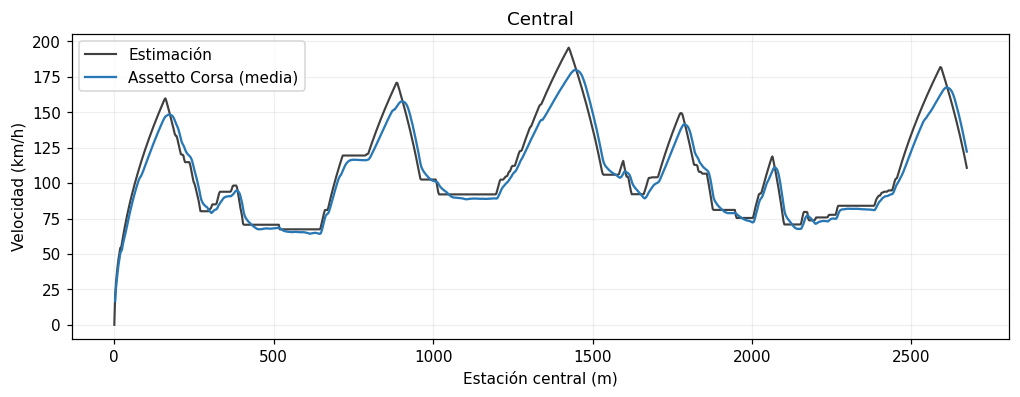

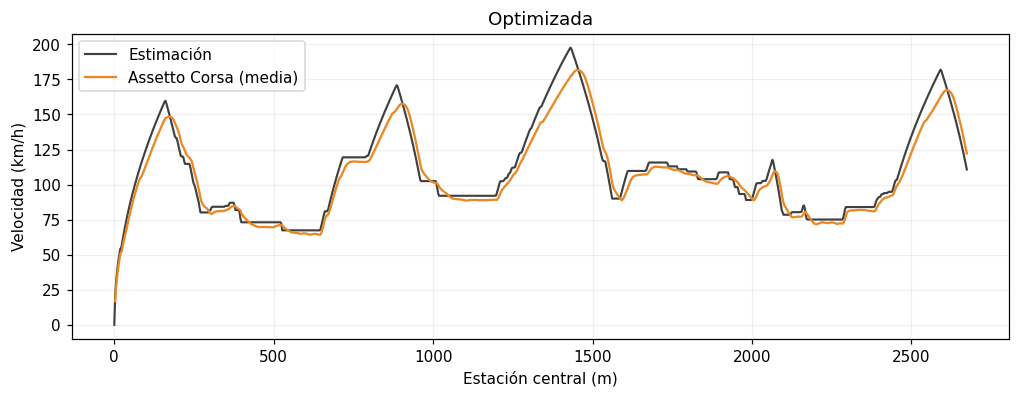

,central,optimizada
MAE (km/h),6.438,6.111


In [6]:
mae={}
for t in TIPOS:
    ref=interp(EST[t],'speed_kmh'); obs=perfil(t,'speed_kmh'); ok=np.isfinite(ref)&np.isfinite(obs)
    mae[t]=np.mean(abs(obs[ok]-ref[ok]))
    fig,ax=plt.subplots();ax.plot(grid,ref,label='Estimación',color='0.25',lw=1.4);ax.plot(grid,obs,label='Assetto Corsa (media)',color=colores[t],lw=1.5);ax.set(title=t.capitalize(),xlabel='Estación central (m)',ylabel='Velocidad (km/h)');ax.legend();plt.show()
display(pd.DataFrame([mae],index=['MAE (km/h)']).round(3))

## 9.4. Rendimiento temporal y transferencia de la optimización
Se compara el tiempo estimado con el tiempo promedio experimental. La transferencia de la mejora se define como $P=100\Delta T_{AC}/\Delta T_{est}$.
Para localizar dónde no se reproduce la mejora esperada, se calcula $G(s)=T_c(s)-T_o(s)$ y $D(s)=G_{est}(s)-G_{AC}(s)$. Un tramo ascendente indica pérdida local de la mejora prevista; uno descendente indica recuperación. Las franjas identifican los sectores modificados.

,Estimación,Assetto Corsa
Tiempo central (s),97.815,101.551
Tiempo optimizado (s),96.006,100.213
Mejora (s),1.809,1.338
Mejora (%),1.849,1.318


Transferencia de la mejora: 73.98%


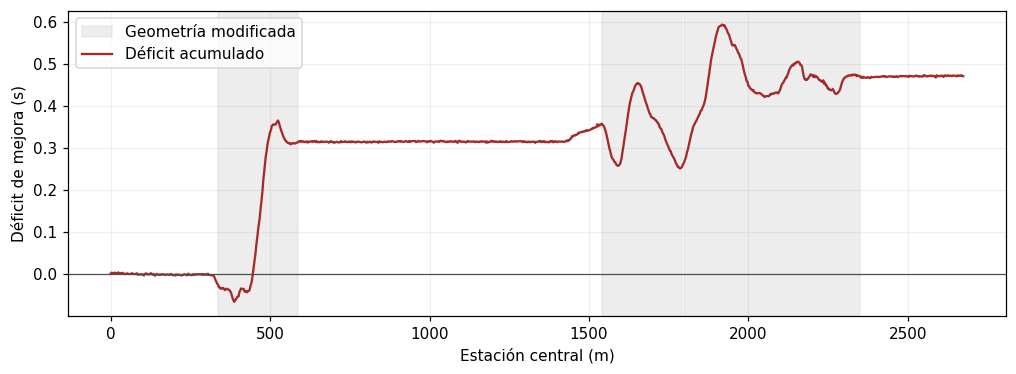

In [7]:
te={t:float(planes[t]['tiempo']) for t in TIPOS}
ta={t:np.mean([r['tiempo_s'] for r in resultados[t]]) for t in TIPOS}
de=te['central']-te['optimizada']; da=ta['central']-ta['optimizada']
display(pd.DataFrame({'Estimación':[te['central'],te['optimizada'],de,100*de/te['central']],'Assetto Corsa':[ta['central'],ta['optimizada'],da,100*da/ta['central']]},index=['Tiempo central (s)','Tiempo optimizado (s)','Mejora (s)','Mejora (%)']).round(3))
print(f'Transferencia de la mejora: {100*da/de:.2f}%')
def tiempo_ac(t,d,r):
    # El cruce exacto se obtiene del JSON, no de la última muestra posterior.
    q=d.loc[(d.distance_m>0)&(d.distance_m<L)&(d.time_s<r['tiempo_s']),['distance_m','time_s']].copy()
    q=pd.concat([pd.DataFrame({'distance_m':[0.],'time_s':[0.]}),q,pd.DataFrame({'distance_m':[L],'time_s':[r['tiempo_s']]})],ignore_index=True)
    return interp(q,'time_s')
T={t:media([tiempo_ac(t,d,r) for d,r in zip(AC[t],resultados[t])]) for t in TIPOS}
D=interp(EST['central'],'time_s')-interp(EST['optimizada'],'time_s')-(T['central']-T['optimizada'])
fig,ax=plt.subplots();ax.fill_between(grid,0,1,where=modificado,transform=ax.get_xaxis_transform(),color='0.85',alpha=.45,label='Geometría modificada');ax.plot(grid,D,color='#a52a2a',label='Déficit acumulado');ax.axhline(0,color='0.3',lw=.8);ax.set(xlabel='Estación central (m)',ylabel='Déficit de mejora (s)');ax.legend();plt.show()

## 9.5. Precisión de seguimiento y restricciones físicas
El error lateral $e_l$ es la desviación firmada respecto a la trayectoria de referencia de cada modalidad. Se utiliza RMSE en vez de MAE porque las desviaciones grandes reciben mayor peso y pueden comprometer la permanencia dentro del corredor:
$$RMSE_l=\sqrt{\frac1N\sum_i e_l^2}.$$
La tabla promedia los RMSE temporales de las diez vueltas. Para localizar errores en pista se calcula el RMSE espacial local de las diez vueltas en cada estación. Tanto la gráfica como el mapa utilizan este mismo indicador, evitando cancelación entre signos. El umbral de 2 m es descriptivo, no un límite de seguridad.

,central,optimizada
RMSE lateral medio (m),0.663,1.323


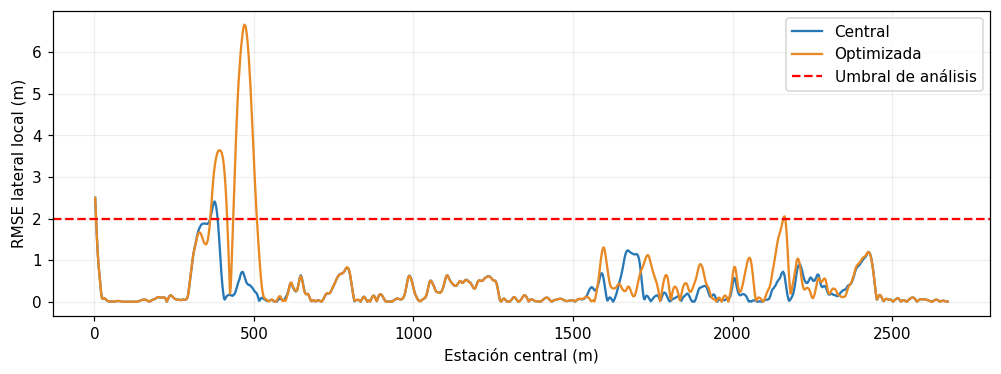

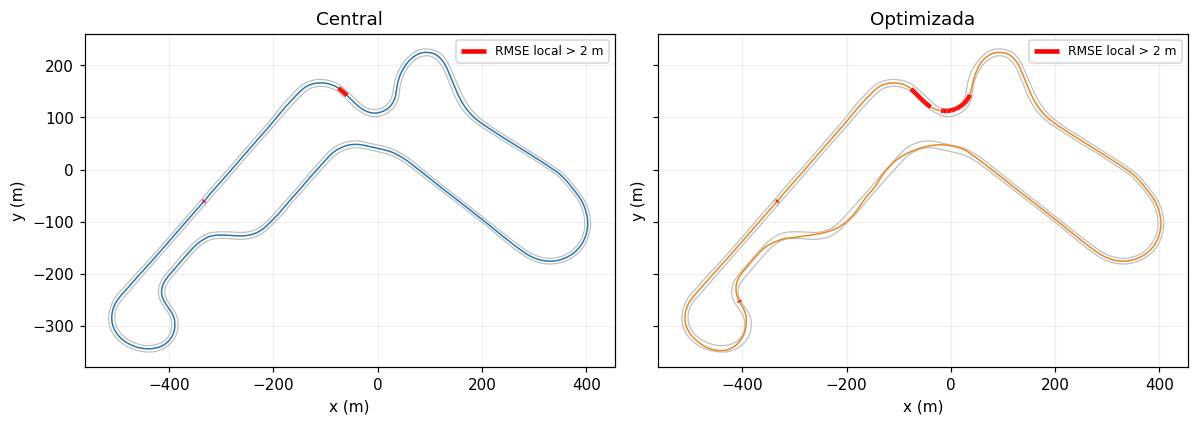

In [8]:
rmse={t:np.mean([np.sqrt(np.mean(d.lateral_error_m**2)) for d in AC[t]]) for t in TIPOS}
display(pd.DataFrame([rmse],index=['RMSE lateral medio (m)']).round(3))
local={t:np.sqrt(media([interp(d,'lateral_error_m')**2 for d in AC[t]])) for t in TIPOS}
umbral=2.
fig,ax=plt.subplots()
for t in TIPOS: ax.plot(grid,local[t],label=t.capitalize(),color=colores[t])
ax.axhline(umbral,color='red',ls='--',label='Umbral de análisis');ax.set(xlabel='Estación central (m)',ylabel='RMSE lateral local (m)');ax.legend();plt.show()
fig,axs=plt.subplots(1,2,figsize=(11,6),sharex=True,sharey=True)
for t,ax in zip(TIPOS,axs):
    for k in ['izquierdo','derecho']:ax.plot(*xy(p[k]).T,color='0.75',lw=.8)
    line=xy(planes[t]['ruta']);ax.plot(*line.T,color=colores[t],lw=1)
    seg=np.stack([line[:-1],line[1:]],axis=1); bad=(local[t][:-1]>umbral)&(local[t][1:]>umbral)
    ax.add_collection(LineCollection(seg[bad],colors='red',linewidths=3,label='RMSE local > 2 m'));ax.set(aspect='equal',title=t.capitalize(),xlabel='x (m)',ylabel='y (m)');ax.legend(loc='best',fontsize=8)
plt.tight_layout();plt.show()

### Adherencia como soporte físico
El círculo de fricción ideal $a_x^2+a_y^2\le(\mu g)^2$ permite examinar la compatibilidad de la telemetría con el límite del modelo. La correspondencia de los ejes se comprueba mediante correlación con $dv/dt$ y $v\,d\psi/dt$; se usa $a_x=g\,accG_2$, $a_y=-g\,accG_0$ si los datos respaldan esa correspondencia. El coeficiente calibrado en frenado longitudinal se aplica a ambos ejes como aproximación isotrópica. La aceleración registrada no constituye una medición directa de las fuerzas de los neumáticos.

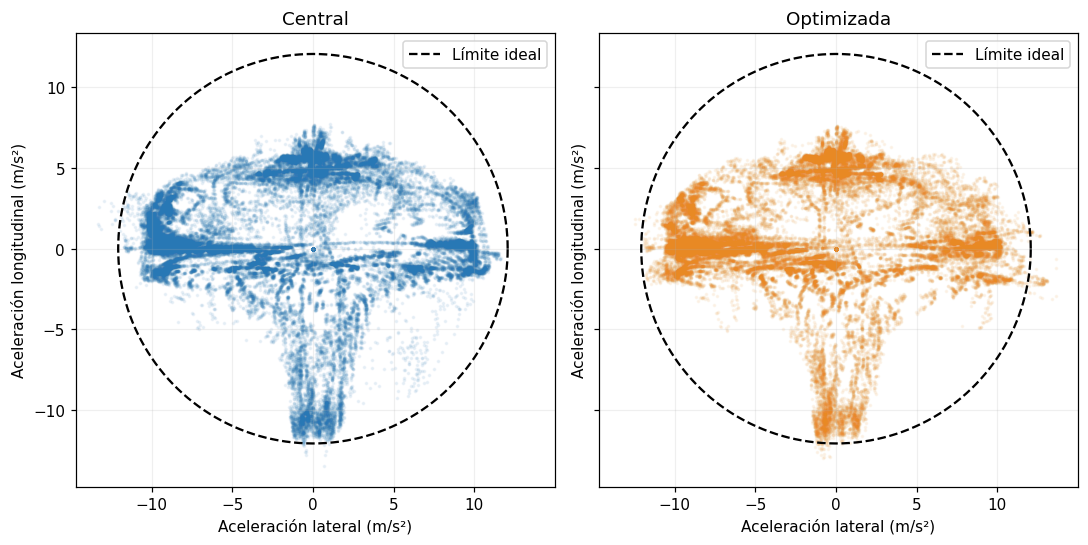

RMSE central: 0.663 m; optimizada: 1.323 m.


In [9]:
G=9.81; mu=float(PARAM['vehiculo']['coef_friccion']); limite=mu*G
corr=[]
for t in TIPOS:
    for d in AC[t]:
        ts=d.time_s.to_numpy();v=d.speed_kmh.to_numpy()/3.6;psi=np.unwrap(d.heading_rad.to_numpy())
        corr.append([np.corrcoef(np.gradient(v,ts),d.accG_2)[0,1],np.corrcoef(v*np.gradient(psi,ts),d.accG_0)[0,1]])
assert np.mean(corr,axis=0)[0]>.8 and np.mean(corr,axis=0)[1]<-.8, 'Revisar correspondencia de ejes.'
th=np.linspace(0,2*np.pi,361)
fig,axs=plt.subplots(1,2,figsize=(10,5),sharex=True,sharey=True)
for t,ax in zip(TIPOS,axs):
    a=pd.concat(AC[t]);ax.scatter(-G*a.accG_0,G*a.accG_2,s=2,alpha=.07,color=colores[t],rasterized=True);ax.plot(limite*np.cos(th),limite*np.sin(th),'k--',label='Límite ideal');ax.set(aspect='equal',title=t.capitalize(),xlabel='Aceleración lateral (m/s²)',ylabel='Aceleración longitudinal (m/s²)');ax.legend()
plt.tight_layout();plt.show()
print(f'RMSE central: {rmse["central"]:.3f} m; optimizada: {rmse["optimizada"]:.3f} m.')

La optimización reduce el tiempo experimental, aunque aumenta el error de seguimiento. El círculo de fricción aporta contexto sobre las restricciones del modelo, pero no demuestra que la adherencia sea la causa de las desviaciones. El error lateral tampoco equivale a una medida completa de estabilidad dinámica.

# 10. Análisis de resultados

## 10.1. Metodología experimental

La utilización de los parámetros físicos definidos en los apartados 3 y 4 y del mismo algoritmo de conducción en ambas modalidades permite centrar la comparación en los efectos de la optimización geométrica y del perfil de velocidad asociado. Se realizaron diez vueltas independientes por modalidad en Assetto Corsa, partiendo del reposo y alternando el orden por pares de ensayos.

Las repeticiones permiten caracterizar la variabilidad de la ejecución. La comparación se limita al vehículo, circuito y configuración estudiados; no constituye una validación universal del modelo.

## 10.2. Optimización geométrica de la trayectoria

Las gráficas del apartado 9.2 muestran que las modificaciones geométricas se concentran en sectores específicos del circuito. Se registraron seis decisiones finales de ápice, con un desplazamiento máximo de aproximadamente 4,90 m respecto a la línea central.

Desde el punto de vista físico, aumentar el radio de giro reduce la aceleración lateral requerida para mantener una velocidad determinada:

$$|a_y|=\frac{v^2}{R}.$$

Esto permite alcanzar velocidades superiores bajo una misma restricción de adherencia. Sin embargo, una trayectoria con mayor radio de giro puede implicar una mayor distancia recorrida. Por ello, la optimización considera el tiempo total de vuelta y no únicamente la reducción de la curvatura.

La trayectoria seleccionada presenta una mejora teórica del 1,849 %. Se trata de una solución mejorada dentro del conjunto de candidatos evaluados, no de un óptimo global demostrado. Una búsqueda más exhaustiva podría encontrar otras mejoras, con un costo computacional adicional.

## 10.3. Capacidad predictiva del perfil de velocidad

El apartado 9.3 muestra un error absoluto medio de 6,438 km/h para la trayectoria central y de 6,111 km/h para la optimizada. Estas magnitudes corresponden a la comparación de la velocidad estimada con el perfil experimental promedio de las diez vueltas, sobre estaciones comunes del circuito.

La proximidad de ambos valores indica que la optimización geométrica no deterioró el ajuste global de los perfiles de velocidad según esta métrica. Las gráficas muestran que el modelo identifica los principales sectores de aceleración y frenado, aunque existen diferencias entre las magnitudes predichas y las observadas.

Estas diferencias podrían estar relacionadas con la representación simplificada de la aceleración y el frenado, el coeficiente de fricción constante y la respuesta del controlador. El modelo permite aproximar el comportamiento longitudinal del vehículo, pero no reproducir exactamente su dinámica.

## 10.4. Rendimiento temporal y transferencia de la optimización

El modelo predijo una reducción del tiempo de vuelta de 1,809 s, mientras que en Assetto Corsa se obtuvo una reducción promedio de 1,338 s. Esto representa aproximadamente el **74 % de la mejora temporal predicha**, según la métrica definida en el apartado 9.4.

Aunque el modelo subestima los tiempos absolutos de vuelta, identifica correctamente una modificación geométrica que mejora el rendimiento experimental. La diferencia de aproximadamente 0,471 s muestra que la ventaja calculada no se traslada por completo al simulador.

La gráfica del déficit temporal permite localizar los sectores en los que se pierde o recupera parte de la ventaja prevista. Al relacionarla con los sectores modificados y los errores laterales, se pueden formular posibles explicaciones físicas de las diferencias, sin asumir que una coincidencia espacial establece causalidad.

El modelo resulta útil para predecir la dirección de la mejora relativa, aun cuando sus estimaciones temporales absolutas presentan limitaciones.

## 10.5. Precisión de seguimiento y adherencia

El RMSE lateral promedio aumentó de 0,663 m a 1,323 m al pasar de la trayectoria central a la optimizada, un incremento aproximado del 99,5 %. Este resultado evidencia un compromiso entre rendimiento temporal y precisión de seguimiento.

Los mapas del apartado 9.5 localizan los sectores cuyo RMSE local supera 2 m. Este umbral permite identificar desviaciones importantes, pero no representa un límite físico de seguridad. Las veinte vueltas se completaron sin que el punto de referencia del vehículo saliera del corredor definido por el programa.

El círculo de fricción ofrece un contexto físico para examinar las aceleraciones observadas frente al límite ideal del modelo. Entre las posibles explicaciones de las desviaciones se encuentran el deslizamiento de los neumáticos, la transferencia de carga, la dinámica lateral no representada explícitamente y la respuesta del controlador. El coeficiente de fricción de 1,23 fue estimado longitudinalmente y aplicado a ambas direcciones bajo el supuesto de isotropía.

Un mayor error lateral no equivale necesariamente a una pérdida de adherencia o de estabilidad dinámica. Tampoco el círculo de fricción permite atribuir por sí solo las desviaciones a un fenómeno específico.

### 10.5.1. Hallazgo cualitativo durante la experimentación

Durante la observación directa de las vueltas en Assetto Corsa, se percibió que algunas desviaciones de la trayectoria central parecían formar trazadas similares a la selección de ápices, aunque estos no habían sido planificados. En cambio, las desviaciones de la trayectoria optimizada parecían manifestarse principalmente como dificultades para reproducir la referencia calculada.

Esta observación podría explicarse por la interacción entre la dinámica vehicular, la inercia y las acciones del controlador. No implica que el vehículo seleccione u optimice autónomamente sus ápices. Además, el menor RMSE de la trayectoria central impide afirmar que esta haya sido más difícil de seguir en términos cuantitativos.

El hallazgo sugiere que la magnitud del error no describe completamente su naturaleza geométrica. Como posible trabajo posterior, se podrían comparar las trazadas experimentales centrales con la línea central y la trayectoria optimizada, para comprobar si las desviaciones se aproximan sistemáticamente a los ápices calculados. Esta hipótesis permanece sin verificar.

# 11. Conclusiones

**a. Capacidad de optimización.** El modelo físico simplificado permitió generar una trayectoria con una reducción estimada del tiempo de vuelta del 1,849 %. La selección de ápices permitió explorar el compromiso entre curvatura, longitud del recorrido y velocidades físicamente admisibles.

**b. Costo computacional.** La búsqueda exhaustiva de combinaciones de ápices puede presentar un crecimiento exponencial del espacio de soluciones a medida que aumenta el número de curvas. El algoritmo implementado utiliza una búsqueda iterativa limitada, por lo que no realiza esa exploración exhaustiva. En este proyecto se adoptó un punto intermedio entre el costo computacional y la calidad de la solución, limitando las pasadas y los candidatos considerados. La trayectoria podría mejorarse con una búsqueda más amplia, aunque no se garantiza una mejora adicional ni un óptimo global.

**c. Precisión del modelo físico.** Los errores absolutos medios de velocidad fueron de 6,438 km/h para la trayectoria central y 6,111 km/h para la optimizada. El modelo identifica los principales cambios del perfil de velocidad y aproxima el comportamiento longitudinal observado, aunque no reproduce exactamente la respuesta dinámica del vehículo.

**d. Transferencia de la optimización.** De los 1,809 s de mejora temporal predichos se obtuvieron experimentalmente 1,338 s, equivalentes a aproximadamente el 74 % de la mejora absoluta esperada. Esto respalda el uso del modelo simplificado para identificar trayectorias que mejoran el rendimiento en un simulador con física más detallada.

**e. Estabilidad y seguridad operacional.** El sistema completó las veinte vueltas experimentales sin que el punto de referencia del vehículo saliera del corredor establecido. Esto proporciona evidencia de una ejecución operacional satisfactoria bajo las condiciones estudiadas. No constituye una garantía general de seguridad, ausencia de deslizamiento o estabilidad dinámica, ni demuestra que toda la carrocería permaneciera dentro de los bordes.

**f. Compromiso entre rendimiento y precisión.** La reducción del tiempo de vuelta estuvo acompañada de un aumento del RMSE lateral de 0,663 m a 1,323 m. Por tanto, minimizar el tiempo estimado no garantiza maximizar la precisión de seguimiento de la trayectoria.

**g. Limitaciones físicas.** El uso de un coeficiente de adherencia constante e isotrópico, la ausencia de un modelo detallado de neumáticos y transferencia de carga, y las limitaciones del controlador pueden contribuir a las diferencias entre predicción y ejecución. Incorporar estos fenómenos podría mejorar la representación física, con un aumento de la complejidad matemática y computacional.

**h. Naturaleza de las desviaciones laterales.** La observación cualitativa de las vueltas centrales sugirió que algunas desviaciones se asemejaban a trazadas con ápices, mientras que en las vueltas optimizadas parecían manifestarse dificultades de seguimiento. Esta posible diferencia geométrica constituye una línea de investigación adicional y requiere comprobación cuantitativa; no evidencia una optimización autónoma por parte del vehículo.

**i. Respuesta a la pregunta de investigación.** El modelo físico simplificado constituye una herramienta viable para predecir y optimizar trayectorias de conducción en las condiciones evaluadas. Aunque presenta errores en los perfiles de velocidad y en los tiempos absolutos, consigue transferir aproximadamente el 74 % de la mejora temporal predicha a Assetto Corsa y completar las veinte vueltas experimentales. Su utilidad reside en identificar mejoras físicamente fundamentadas con un costo de modelado reducido, reconociendo el compromiso entre rendimiento y precisión de seguimiento.

## 12. Declaración de uso de IA
| Herramienta | Uso |
|---|---|
| Claude (Anthropic) | Orden y estructura de la versión inicial del notebook, texto explicativo y código de análisis, según la declaración original. |
| ChatGPT (OpenAI) | Revisión y reorganización del notebook, asistencia en código, análisis de datos experimentales, gráficas, redacción y revisión de conclusiones. |

Los integrantes deben verificar la declaración antes de entregar y completar otros usos que correspondan.

## 13. Referencias

- Kunos Simulazioni. *Assetto Corsa* (2014).
- Autódromo de Tocancipá 2.0, mod para Assetto Corsa hecho para la APVS (Asociación de Pilotos Virtuales Sudamericanos).
- Datos del circuito real (longitud, número de curvas y desnivel): LapMeta, ficha del Autódromo de Tocancipá.
- *A Simulation Benchmark for Autonomous Racing* (Assetto Corsa Gym), arXiv:2407.16680 (2024).
- Pendiente de completar y verificar: texto guía del curso y el artículo usado para las ecuaciones de geometría (`integrar_pista_desde_curvatura_paper`).